In [1198]:
import json 
import os
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt
import torch
import torch.nn as nn
from torchvision import models, transforms
import torch.nn.functional as F
import random
import cv2



In [1199]:
!pip install scikit-image

In [1200]:

from skimage.segmentation import mark_boundaries


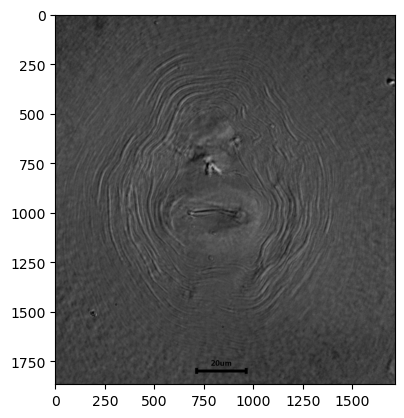

In [1201]:
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB') 
        
img = get_image('/home/dbtproject/barsha/New_Image/test/Class1_Incognita/M_incognita_0001 (75).JPG')
plt.imshow(img)

In [1202]:
# img_r = get_image('/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_2_PP_4.tiff')
# img_r = img_r.rotate(180, expand = True)
# plt.imshow(img_r)

In [1203]:
# resize and take the center part of image to what our model expects
def get_input_transform():
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225])       
    transf = transforms.Compose([
        transforms.Resize(232),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        normalize
    ])    

    return transf

def get_input_tensors(img):
    transf = get_input_transform()
    # unsqeeze converts single image to batch of 1
    return transf(img).unsqueeze(0)

In [1204]:
# def get_input_tensors(img):
#     transf = get_input_transform()
#     # unsqeeze converts single image to batch of 1
#     return transf(img_r).unsqueeze(0)

In [1205]:
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [1206]:
# ResNet-50 Model

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 2)
model.load_state_dict(torch.load("/home/dbtproject/barsha/np_code_new/checkpoints_new_50/best_weights_cv.pth", map_location=device))
model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [1207]:
class_names = [
    "Meloidogyne incognita",
    "Meloidogyne javanica"
]

In [1208]:
img_t = get_input_tensors(img)
img_t = img_t.to(device)
logits = model(img_t)
probs = F.softmax(logits, dim=1)
topk = probs.topk(2)

results = [
    (float(p), int(c), class_names[c])
    for p, c in zip(topk.values[0], topk.indices[0])
]

results

[(0.9162610173225403, 0, 'Meloidogyne incognita'),
 (0.08373893797397614, 1, 'Meloidogyne javanica')]

In [1209]:
# img_tf = get_input_tensors(img_r)
# img_tf = img_t.to(device)
# logits = model(img_tf)
# probs = F.softmax(logits, dim=1)
# topk = probs.topk(3)

# results = [
#     (float(p), int(c), class_names[c])
#     for p, c in zip(topk.values[0], topk.indices[0])
# ]

# results


In [1210]:
def get_pil_transform():
    transf = transforms.Compose([
        transforms.Resize(232),
        transforms.CenterCrop(224),
    ])    

    return transf

def get_preprocess_transform():
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225])       
    
    tf = transforms.Compose([
        transforms.ToTensor(),
        normalize    
    ])

    return tf 

pil_tf = get_pil_transform()
preprocess_tf = get_preprocess_transform()



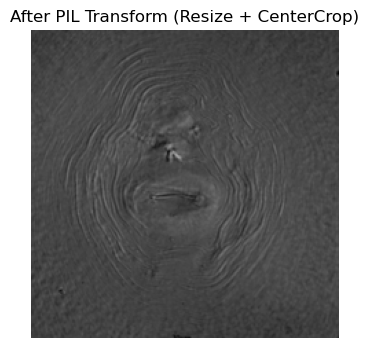

In [1211]:
import matplotlib.pyplot as plt

pil_img = pil_tf(img)   # still PIL.Image

plt.figure(figsize=(4,4))
plt.imshow(pil_img)
plt.axis("off")
plt.title("After PIL Transform (Resize + CenterCrop)")
plt.show()


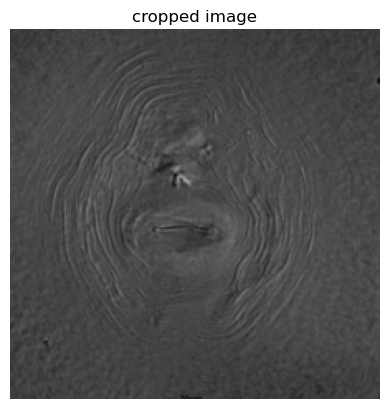

In [1212]:
import torch

def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(3,1,1)
    std = torch.tensor(std).view(3,1,1)
    return tensor * std + mean


tensor_img = preprocess_tf(pil_img)   # (3,224,224)

denorm_img = denormalize(
    tensor_img,
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Clamp to valid range
denorm_img = denorm_img.clamp(0, 1)

# Convert C,H,W → H,W,C
img_np = denorm_img.permute(1, 2, 0).cpu().numpy()



plt.imshow(img_np)
plt.axis("off")
plt.title("cropped image")
plt.show()


In [1213]:
def batch_predict(images):
    model.to(device)
    model.eval()
    batch = torch.stack(tuple(preprocess_tf(i) for i in images), dim = 0)
    batch = batch.to(device)

    logits = model(batch)
    probs = F.softmax(logits, dim = 1)
    return probs.detach().cpu().numpy()

In [1214]:
test_pred = batch_predict([pil_tf(img)])
test_pred.squeeze().argmax()


np.int64(0)

In [1215]:
# test_pred_r = batch_predict([pil_tf(img_r)])
# test_pred_r.squeeze().argmax()


In [1216]:
pred_class = test_pred.squeeze().argmax()
class_names[pred_class]


'Meloidogyne incognita'

In [1217]:
# pred_class_r = test_pred_r.squeeze().argmax()
# class_names[pred_class_r]

In [1218]:
confidence = float(np.max(test_pred))
print("Confidence:", confidence)

Confidence: 0.9162610173225403


In [1219]:
#use lime to explain the model
!pip install lime


In [1220]:
from lime import lime_image
from skimage.segmentation import slic

# def segmentation_fn(image):
#     return slic(
#         image,
#         n_segments=300,
#         compactness=10,
#         sigma=1,
#         start_label=0
#     )

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(np.array(pil_tf(img)),
                                         batch_predict, #classfication function
                                         top_labels = 3,
                                         hide_color = None,
                                         num_samples = 3000)
                                        #  segmentation_fn=segmentation_fn)


100%|██████████| 3000/3000 [00:08<00:00, 373.37it/s]


In [1221]:
# # ORIGINAL IMAGE
# import cv2
# original_img = np.array(img)
# orig_h, orig_w = original_img.shape[:2]

# # Resize mask to original resolution
# mask_resized = cv2.resize(
#     mask.astype(np.uint8),
#     (orig_w, orig_h),
#     interpolation=cv2.INTER_NEAREST
# )

# # Overlay boundary on original image
# lime_on_original = mark_boundaries(
#     original_img / 255.0,
#     mask_resized
# )

# plt.imshow(lime_on_original)
# plt.axis("off")
# plt.title("LIME on Original Image")
# plt.show()


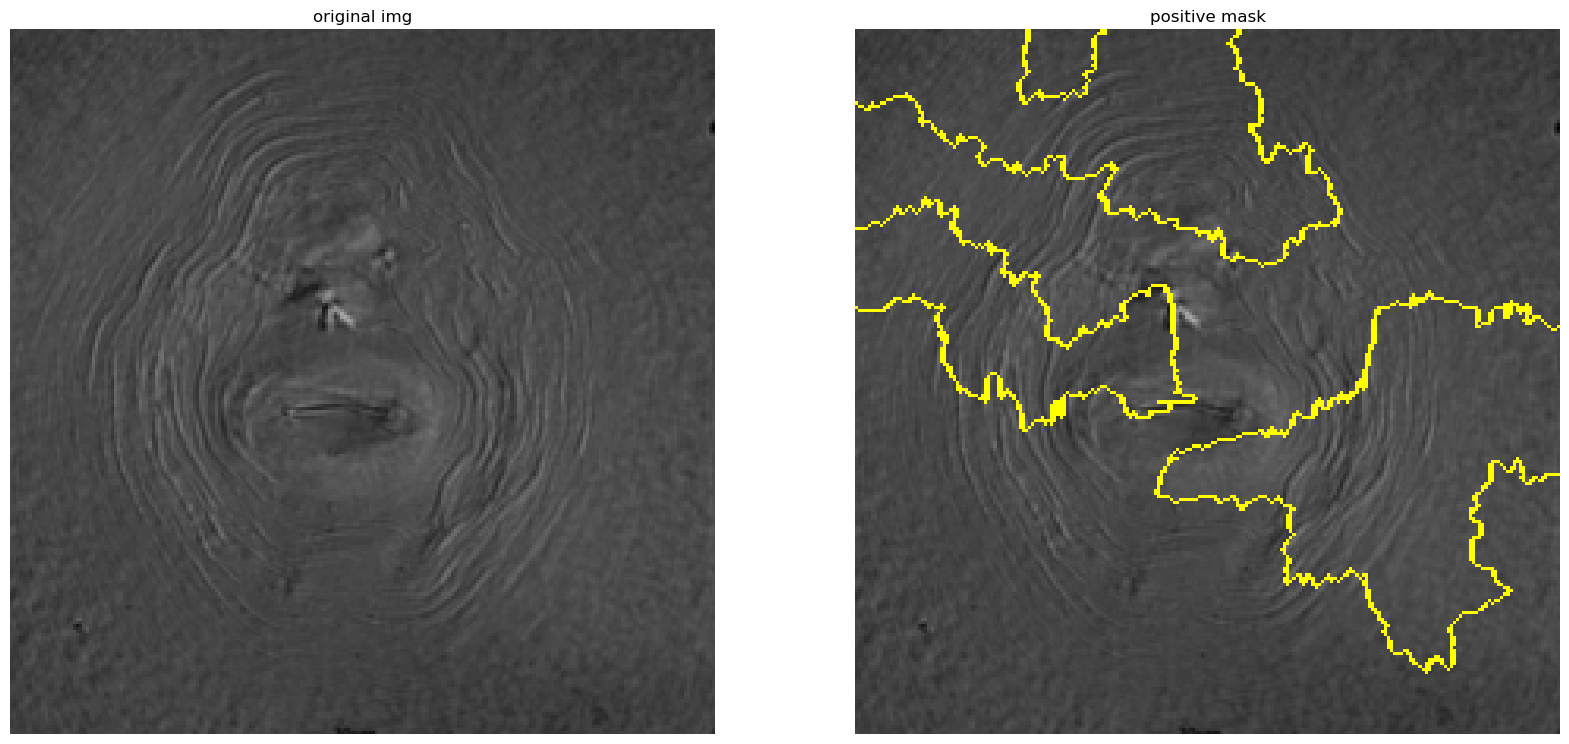

In [1222]:
# explainer = lime_image.LimeImageExplainer()
# explanation = explainer.explain_instance(np.array(pil_tf(img)),
#                                          batch_predict, #classfication function
#                                          top_labels = 3,
#                                          hide_color = None,
#                                          num_samples = 3000)
#                                         #  segmentation_fn=segmentation_fn)

fig, axes = plt.subplots(1,2, figsize = (20,10))

axes[0].imshow(pil_tf(img))
axes[0].axis('off')
axes[0].set_title('original img')

temp, mask = explanation.get_image_and_mask(pred_class,
                                            positive_only = True,
                                            negative_only = False,
                                            num_features = 10,
                                            hide_rest = False)

img_boundary2 = mark_boundaries(temp/255.0, mask)
axes[1].imshow(img_boundary2)
axes[1].set_title('positive mask')
axes[1].axis('off')

# temp, mask = explanation.get_image_and_mask(pred_class,
#                                             positive_only = False,
#                                             negative_only = True,
#                                             num_features = 10,
#                                             hide_rest = True)

# img_boundary = mark_boundaries(temp/255.0, mask)
# axes[2].imshow(img_boundary)
# axes[2].set_title('negative mask')
# axes[2].axis('off')



plt.show()

In [1223]:
#  explainer = lime_image.LimeImageExplainer()
# explanation = explainer.explain_instance(np.array(pil_tf(img_r)),
#                                          batch_predict, #classfication function
#                                          top_labels = 3,
#                                          hide_color = None,
#                                          num_samples = 3000)
#                                         #  segmentation_fn=segmentation_fn)

# fig, axes = plt.subplots(1,2, figsize = (20,10))

# axes[0].imshow(pil_tf(img_r))
# axes[0].axis('off')
# axes[0].set_title('original img')

# temp, mask = explanation.get_image_and_mask(pred_class,
#                                             positive_only = True,
#                                             negative_only = False,
#                                             num_features = 10,
#                                             hide_rest = False)

# img_boundary1 = mark_boundaries(temp/255.0, mask)
# axes[1].imshow(img_boundary1)
# axes[1].set_title('positive mask')
# axes[1].axis('off')

# # temp, mask = explanation.get_image_and_mask(pred_class,
# #                                             positive_only = False,
# #                                             negative_only = True,
# #                                             num_features = 10,
# #                                             hide_rest = True)

# # img_boundary = mark_boundaries(temp/255.0, mask)
# # axes[2].imshow(img_boundary)
# # axes[2].set_title('negative mask')
# # axes[2].axis('off')



# plt.show()

In [1224]:
# plt.figure(figsize = (16,14))

# plt.subplot(1,2,1)
# plt.title('org img')
# plt.imshow(img_boundary2)
# plt.axis('off')


# plt.subplot(1,2,2)
# plt.title('roatated img')
# plt.imshow(img_boundary1)
# plt.axis('off')

In [1225]:
explanation.top_labels[0]  # highest confidence class


np.int64(0)

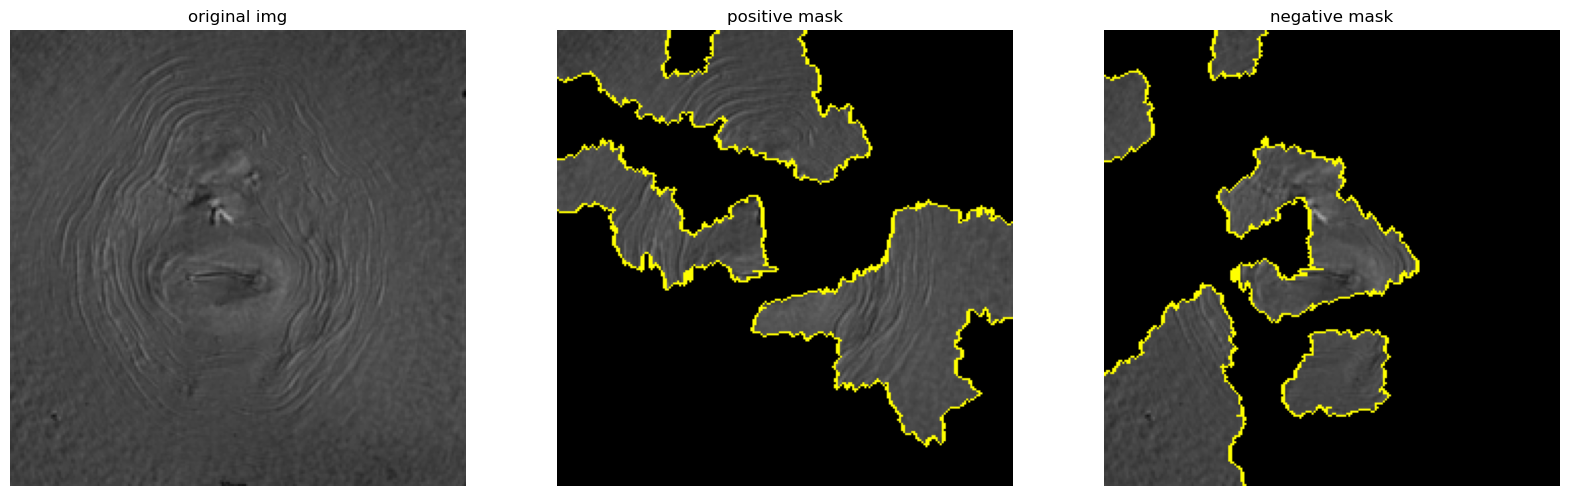

In [1226]:
fig, axes = plt.subplots(1,3, figsize = (20,10))

axes[0].imshow(pil_tf(img))
axes[0].axis('off')
axes[0].set_title('original img')

temp, mask = explanation.get_image_and_mask(pred_class,
                                            positive_only = True,
                                            negative_only = False,
                                            num_features = 10,
                                            hide_rest = True)

img_boundary = mark_boundaries(temp/255.0, mask)
axes[1].imshow(img_boundary)
axes[1].set_title('positive mask')
axes[1].axis('off')

temp, mask = explanation.get_image_and_mask(pred_class,
                                            positive_only = False,
                                            negative_only = True,
                                            num_features = 10,
                                            hide_rest = True)

img_boundary = mark_boundaries(temp/255.0, mask)
axes[2].imshow(img_boundary)
axes[2].set_title('negative mask')
axes[2].axis('off')



plt.show()

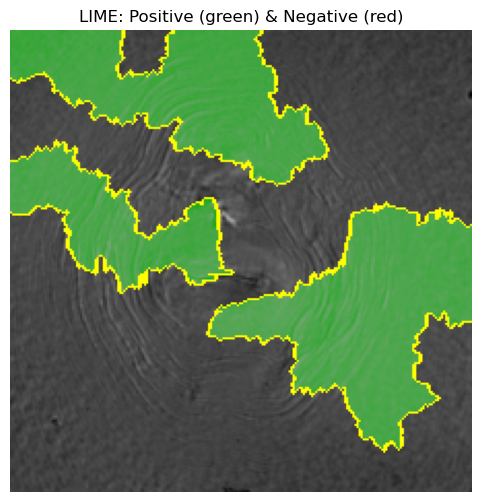

In [1227]:
temp, mask = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False
)

img_boundary = mark_boundaries(temp / 255.0, mask)
plt.figure(figsize=(6,6))
plt.imshow(img_boundary)
plt.axis('off')
plt.title("LIME: Positive (green) & Negative (red)")
plt.show()


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

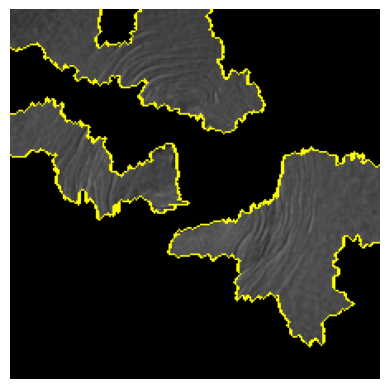

In [1228]:
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0],
                                            positive_only = True,
                                            negative_only = False,
                                            num_features = 10,
                                            hide_rest = True)

img_boundry= mark_boundaries(temp/255.0, mask)

plt.imshow(img_boundry)
plt.axis('off')



In [1229]:
original_img = np.array(img)   # Full-resolution image (H × W × 3)
lime_mask_224 = mask                    # 224 × 224 (from LIME)


orig_h, orig_w = original_img.shape[:2]

# Resize so shorter side = 256 (Torchvision behavior)
if orig_h < orig_w:
    resized_h = 232
    resized_w = int(orig_w * 232 / orig_h)
else:
    resized_w = 232
    resized_h = int(orig_h * 232 / orig_w)


crop_size = 224

crop_y = (resized_h - crop_size) // 2
crop_x = (resized_w - crop_size) // 2

scale_y = orig_h / resized_h
scale_x = orig_w / resized_w

orig_y = int(crop_y * scale_y)
orig_x = int(crop_x * scale_x)

orig_h_crop = int(crop_size * scale_y)
orig_w_crop = int(crop_size * scale_x)


In [1230]:
full_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)


In [1231]:
mask_in_original_scale = cv2.resize(
    lime_mask_224.astype(np.uint8),
    (orig_w_crop, orig_h_crop),
    interpolation=cv2.INTER_NEAREST   # IMPORTANT: no smoothing
)


In [1232]:
full_mask[
    orig_y:orig_y + orig_h_crop,
    orig_x:orig_x + orig_w_crop
]= mask_in_original_scale


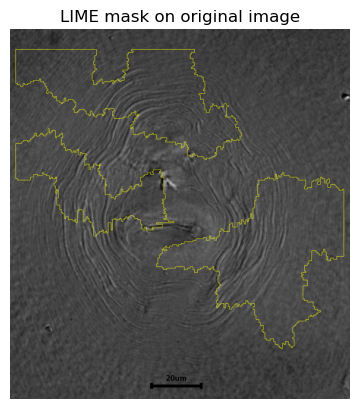

In [1233]:
from skimage.segmentation import mark_boundaries

overlay = mark_boundaries(
    original_img / 255.0,
    full_mask,
    color=(1, 1, 0),
    mode="thick"
)

plt.imshow(overlay)
plt.axis("off")
plt.title("LIME mask on original image")
plt.show()


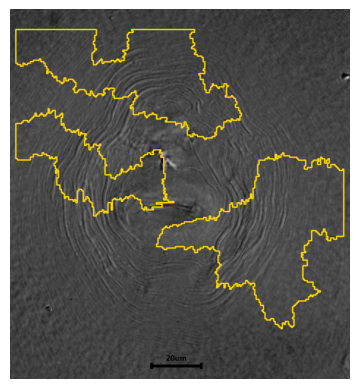

(1866, 1715, 3)


In [1234]:
import cv2

overlay = original_img.copy()

# Find contours
contours, _ = cv2.findContours(
    full_mask.astype(np.uint8),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Draw thick contours
cv2.drawContours(
    overlay,
    contours,
    -1,
    color=(255, 215, 0),  # dark yellow
    thickness=5           # ← FULL CONTROL HERE
)

plt.imshow(overlay)
plt.axis("off")
plt.show()
print(overlay.shape)

In [1235]:
# temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only = False, num_features=10, hide_rest=False)
# img_boundry= mark_boundaries(temp/255.0, mask)
# plt.imshow(img_boundry)

In [1236]:
print("Unique mask values:", np.unique(mask))


Unique mask values: [0 1]


In [1237]:
temp, mask = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,   # or False if needed
    num_features=10,
    hide_rest=False
)

In [1238]:
import numpy as np

binary_mask = (mask > 0).astype(np.uint8)


In [1239]:

import cv2

contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)


In [1240]:
img_boundary = mark_boundaries(temp/255.0, mask).copy()
img = (img_boundary * 255).astype(np.uint8)

for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)

    cv2.rectangle(
        img,
        (x, y),
        (x + w, y + h),
        (0, 0, 255),  
        1
    )


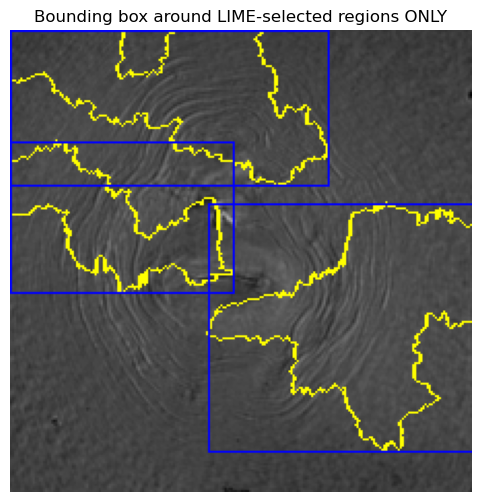

In [1241]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title("Bounding box around LIME-selected regions ONLY")
plt.show()


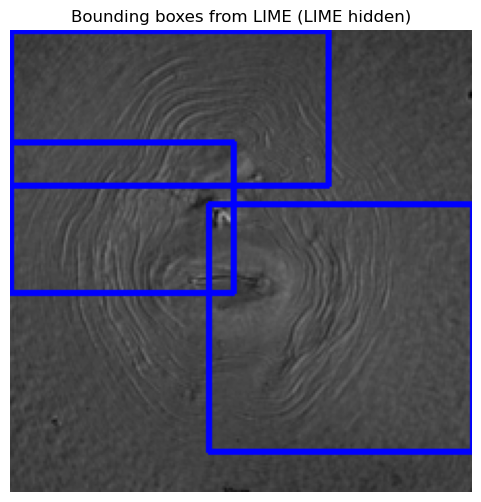

In [1242]:
img = (temp / 255.0)
img = (img * 255).astype(np.uint8)


for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)

    cv2.rectangle(
        img,
        (x, y),
        (x + w, y + h),
        (0, 0, 255),  #blue box
        2
    )
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title("Bounding boxes from LIME (LIME hidden)")
plt.show()
